## CAP6938 AI Knowledge TESTER

### Part 1: 

TEST

In [1]:
import sys
# initialization code
import numpy as np
from keras.datasets import mnist
%matplotlib inline
from matplotlib import pyplot as plt
from scipy import stats
import torch
import torch.nn as nn

print("Python:", sys.version)
print("Executable:", sys.executable)

packages = [
    "torch",
    "torchvision",
    "transformers",
    "datasets",
    "sentence_transformers",
    "PIL",
    "numpy",
    "matplotlib",
]

for package in packages:
    try:
        module = __import__(package)
        version = getattr(module, "__version__", "installed (version unavailable)")
        print(f"{package:22s} OK   {version}")
    except ImportError as e:
        print(f"{package:22s} MISSING   {e}")

Python: 3.10.4 (tags/v3.10.4:9d38120, Mar 23 2022, 23:13:41) [MSC v.1929 64 bit (AMD64)]
Executable: C:\Python310\python.exe
torch                  OK   2.5.1+cu121
torchvision            OK   0.20.1+cu121
transformers           OK   5.17.0
datasets               OK   4.8.4
sentence_transformers  OK   6.0.1
PIL                    OK   12.2.0
numpy                  OK   1.26.4
matplotlib             OK   3.7.2


In [2]:
# Sets device to "cuda" if a GPU is available  (in Colabs, enable GPU by Edit->Notebook Settings-->Hardware Accelerator=GPU)
device = "cuda" if torch.cuda.is_available() else 'cpu'
print(device) # make sure you're using GPU instance
print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version used by torch:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

cuda
Torch version: 2.5.1+cu121
CUDA available: True
CUDA version used by torch: 12.1
GPU: NVIDIA GeForce RTX 2070


#### 1a


In [3]:
try:
    import faiss
    print("faiss                  OK  ", faiss.__version__)
except ImportError as e:
    print("faiss                  MISSING  ", e)

faiss                  OK   1.15.1


In [4]:
%load_ext autoreload
%autoreload 2

In [6]:
import json
from pathlib import Path
from pprint import pprint

DATA_DIR = Path("../Yelp_JSON")
BUSINESS_FILE = DATA_DIR / "yelp_academic_dataset_business.json"

with BUSINESS_FILE.open("r", encoding="utf-8") as f:
    first_business = json.loads(f.readline())

pprint(first_business)

{'address': '1616 Chapala St, Ste 2',
 'attributes': {'ByAppointmentOnly': 'True'},
 'business_id': 'Pns2l4eNsfO8kk83dixA6A',
 'categories': 'Doctors, Traditional Chinese Medicine, Naturopathic/Holistic, '
               'Acupuncture, Health & Medical, Nutritionists',
 'city': 'Santa Barbara',
 'hours': None,
 'is_open': 0,
 'latitude': 34.4266787,
 'longitude': -119.7111968,
 'name': 'Abby Rappoport, LAC, CMQ',
 'postal_code': '93101',
 'review_count': 7,
 'stars': 5.0,
 'state': 'CA'}


In [7]:
import json

restaurant_count = 0
total_businesses = 0
restaurant_cities = {}

with BUSINESS_FILE.open("r", encoding="utf-8") as f:
    for line in f:
        business = json.loads(line)
        total_businesses += 1

        categories = business.get("categories") or ""
        category_list = [
            category.strip().lower()
            for category in categories.split(",")
        ]

        if "restaurants" in category_list:
            restaurant_count += 1

            city = business.get("city", "Unknown")
            restaurant_cities[city] = restaurant_cities.get(city, 0) + 1

print(f"Total businesses: {total_businesses:,}")
print(f"Restaurants: {restaurant_count:,}")

print("\nTop 10 cities by restaurant count:")
for city, count in sorted(
    restaurant_cities.items(),
    key=lambda item: item[1],
    reverse=True
)[:10]:
    print(f"{city}: {count:,}")

Total businesses: 150,346
Restaurants: 52,268

Top 10 cities by restaurant count:
Philadelphia: 5,852
Tampa: 2,960
Indianapolis: 2,862
Nashville: 2,502
Tucson: 2,466
New Orleans: 2,259
Edmonton: 2,166
Saint Louis: 1,790
Reno: 1,286
Boise: 847


In [8]:
import json
from pprint import pprint

REVIEW_FILE = DATA_DIR / "yelp_academic_dataset_review.json"

# Step 1: Select a Tampa restaurant with at least 100 reviews.
selected_restaurant = None

with BUSINESS_FILE.open("r", encoding="utf-8") as f:
    for line in f:
        business = json.loads(line)

        categories = [
            c.strip().lower()
            for c in (business.get("categories") or "").split(",")
        ]

        if (
            business.get("city") == "Tampa"
            and "restaurants" in categories
            and business.get("review_count", 0) >= 100
        ):
            selected_restaurant = business
            break

if selected_restaurant is None:
    raise ValueError("No matching Tampa restaurant found.")

print("SELECTED RESTAURANT")
print(f"Name: {selected_restaurant['name']}")
print(f"Business ID: {selected_restaurant['business_id']}")
print(f"Categories: {selected_restaurant['categories']}")
print(f"Rating: {selected_restaurant['stars']}")
print(f"Review count: {selected_restaurant['review_count']}")

# Step 2: Retrieve up to five reviews for this restaurant.
reviews = []
business_id = selected_restaurant["business_id"]

with REVIEW_FILE.open("r", encoding="utf-8") as f:
    for line in f:
        review = json.loads(line)

        if review["business_id"] == business_id:
            reviews.append(review)

            if len(reviews) == 5:
                break

print(f"\nFOUND {len(reviews)} REVIEWS\n")

for i, review in enumerate(reviews, start=1):
    print(f"{'=' * 60}")
    print(f"REVIEW {i}")
    print(f"Stars: {review['stars']}")
    print(f"Date: {review['date']}")
    print(f"Text:\n{review['text']}\n")

SELECTED RESTAURANT
Name: O'Briens Irish Pub
Business ID: Ucl9Vo5lwrUmYbV8Dv8X5g
Categories: Bars, Pubs, Nightlife, Arts & Entertainment, Irish, Restaurants, Music Venues
Rating: 4.0
Review count: 108

FOUND 5 REVIEWS

REVIEW 1
Stars: 3.0
Date: 2013-12-08 23:11:18
Text:
I must say that this location is much better than the old location they used to occupy further south in Carrollwood.  There's always plenty of parking and it's a pretty convenient location.  My usual adventures here have been for their annual St. Patrick's Day blowout, which is under a huge tent outdoors, and to watch Gator football games as they are the north Tampa watch location for the Tampa Gator Club.  I've always been met with attentive servers and bartenders every time I have visited.  The food is your average run of the mill Irish bar food, but I think the main attraction is the atmosphere this place provides.

REVIEW 2
Stars: 1.0
Date: 2014-06-30 13:51:09
Text:
I was a huge fan of the old O'Briens with the dive

## Part 2: Tampa restaurant business subset

In [9]:
import json

TAMPA_BUSINESS_FILE = DATA_DIR / "tampa_restaurants.json"

restaurant_count = 0

with BUSINESS_FILE.open("r", encoding="utf-8") as source:
    with TAMPA_BUSINESS_FILE.open("w", encoding="utf-8") as destination:

        for line in source:
            business = json.loads(line)

            categories = [
                category.strip().lower()
                for category in (business.get("categories") or "").split(",")
            ]

            if (
                business.get("city", "").strip().lower() == "tampa"
                and "restaurants" in categories
            ):
                destination.write(json.dumps(business) + "\n")
                restaurant_count += 1

print(f"Tampa restaurants saved: {restaurant_count:,}")
print(f"Output file: {TAMPA_BUSINESS_FILE}")
print(f"File size: {TAMPA_BUSINESS_FILE.stat().st_size / (1024**2):.2f} MB")

Tampa restaurants saved: 2,967
Output file: ..\Yelp_JSON\tampa_restaurants.json
File size: 3.47 MB


#### 2a


In [10]:
TAMPA_REVIEW_FILE = DATA_DIR / "tampa_restaurant_reviews.jsonl"

# Load the IDs of our Tampa restaurants into a set.
tampa_business_ids = set()

with TAMPA_BUSINESS_FILE.open("r", encoding="utf-8") as f:
    for line in f:
        business = json.loads(line)
        tampa_business_ids.add(business["business_id"])

print(f"Tampa business IDs loaded: {len(tampa_business_ids):,}")

# Stream through the original Yelp review dataset.
total_reviews = 0
tampa_reviews = 0

with REVIEW_FILE.open("r", encoding="utf-8") as source:
    with TAMPA_REVIEW_FILE.open("w", encoding="utf-8") as destination:

        for line in source:
            review = json.loads(line)
            total_reviews += 1

            if review["business_id"] in tampa_business_ids:
                destination.write(line)
                tampa_reviews += 1

print(f"\nTotal Yelp reviews scanned: {total_reviews:,}")
print(f"Tampa restaurant reviews saved: {tampa_reviews:,}")
print(f"Output file: {TAMPA_REVIEW_FILE}")
print(f"File size: {TAMPA_REVIEW_FILE.stat().st_size / (1024**2):.2f} MB")

Tampa business IDs loaded: 2,967

Total Yelp reviews scanned: 6,990,280
Tampa restaurant reviews saved: 303,691
Output file: ..\Yelp_JSON\tampa_restaurant_reviews.jsonl
File size: 214.43 MB


#### 2b



In [11]:
# Verify that every Tampa review references a valid Tampa restaurant.

total_reviews = 0
valid_reviews = 0
invalid_reviews = 0
restaurants_with_reviews = set()

with TAMPA_REVIEW_FILE.open("r", encoding="utf-8") as f:
    for line in f:
        review = json.loads(line)
        total_reviews += 1

        business_id = review["business_id"]

        if business_id in tampa_business_ids:
            valid_reviews += 1
            restaurants_with_reviews.add(business_id)
        else:
            invalid_reviews += 1

restaurants_without_reviews = tampa_business_ids - restaurants_with_reviews

print("TAMPA DATA INTEGRITY CHECK")
print("-" * 40)
print(f"Total reviews checked:        {total_reviews:,}")
print(f"Valid reviews:                {valid_reviews:,}")
print(f"Invalid reviews:              {invalid_reviews:,}")
print(f"Restaurants with reviews:     {len(restaurants_with_reviews):,}")
print(f"Restaurants without reviews:  {len(restaurants_without_reviews):,}")

if invalid_reviews == 0:
    print("\nPASS: All reviews reference valid Tampa restaurants.")
else:
    print("\nFAIL: Some reviews reference unknown businesses.")

TAMPA DATA INTEGRITY CHECK
----------------------------------------
Total reviews checked:        303,691
Valid reviews:                303,691
Invalid reviews:              0
Restaurants with reviews:     2,967
Restaurants without reviews:  0

PASS: All reviews reference valid Tampa restaurants.


## Part 3: Test utilities

In [12]:
from data_loader import load_restaurants, get_restaurant

restaurants = load_restaurants()

print(f"Restaurants loaded: {len(restaurants):,}")

# Retrieve our previously examined restaurant.
business_id = "Ucl9Vo5lwrUmYbV8Dv8X5g"

restaurant = get_restaurant(restaurants, business_id)

if restaurant:
    print(f"Name: {restaurant['name']}")
    print(f"City: {restaurant['city']}")
    print(f"Rating: {restaurant['stars']}")
    print(f"Reviews: {restaurant['review_count']}")
else:
    print("Restaurant not found.")

Restaurants loaded: 2,967
Name: O'Briens Irish Pub
City: Tampa
Rating: 4.0
Reviews: 108


In [13]:
from review_retrieval import load_reviews, get_reviews

reviews_by_business = load_reviews()

print(f"Restaurants with reviews: {len(reviews_by_business):,}")
print(f"Total reviews loaded: {sum(len(r) for r in reviews_by_business.values()):,}")

# Use the same restaurant from our previous test.
business_id = "Ucl9Vo5lwrUmYbV8Dv8X5g"

restaurant_reviews = get_reviews(reviews_by_business, business_id)

print(f"\nReviews for {restaurants[business_id]['name']}: {len(restaurant_reviews)}")

# Display the first review.
if restaurant_reviews:
    review = restaurant_reviews[0]

    print(f"\nStars: {review['stars']}")
    print(f"Date: {review['date']}")
    print(f"Text:\n{review['text']}")

Restaurants with reviews: 2,967
Total reviews loaded: 303,691

Reviews for O'Briens Irish Pub: 115

Stars: 3.0
Date: 2013-12-08 23:11:18
Text:
I must say that this location is much better than the old location they used to occupy further south in Carrollwood.  There's always plenty of parking and it's a pretty convenient location.  My usual adventures here have been for their annual St. Patrick's Day blowout, which is under a huge tent outdoors, and to watch Gator football games as they are the north Tampa watch location for the Tampa Gator Club.  I've always been met with attentive servers and bartenders every time I have visited.  The food is your average run of the mill Irish bar food, but I think the main attraction is the atmosphere this place provides.


In [14]:
from restaurant_search import search_restaurants

results = search_restaurants(
    restaurants,
    cuisine="Italian",
    min_stars=4.0,
    min_reviews=50
)

print(f"Matching restaurants: {len(results):,}\n")

for business in results[:10]:
    print(
        f"{business['name']:<40} "
        f"Stars: {business['stars']:.1f}  "
        f"Reviews: {business['review_count']}"
    )

Matching restaurants: 73

Mirro's Pizzeria                         Stars: 5.0  Reviews: 111
OLIVIA                                   Stars: 4.5  Reviews: 545
Pane Rustica                             Stars: 4.5  Reviews: 468
Osteria Natalina                         Stars: 4.5  Reviews: 400
Due Amici                                Stars: 4.5  Reviews: 350
Oggi Italian                             Stars: 4.5  Reviews: 345
Piccola Italia Bistro                    Stars: 4.5  Reviews: 289
Vino E Pasta                             Stars: 4.5  Reviews: 271
La Terrazza Ristorante Italiano          Stars: 4.5  Reviews: 210
Magdalena's Pizzeria                     Stars: 4.5  Reviews: 178


In [15]:
# Examine reviews for the top three Italian restaurants.

for business in results[:3]:
    business_id = business["business_id"]
    reviews = get_reviews(reviews_by_business, business_id)

    print("=" * 70)
    print(f"Restaurant: {business['name']}")
    print(f"Rating: {business['stars']}")
    print(f"Available reviews: {len(reviews)}")

    # Display the first two reviews.
    for review in reviews[:2]:
        print(f"\nReview rating: {review['stars']}")
        print(f"Date: {review['date']}")
        print(f"Text: {review['text']}")

    print()

Restaurant: Mirro's Pizzeria
Rating: 5.0
Available reviews: 119

Review rating: 5.0
Date: 2019-01-15 17:24:29
Text: Best NY style pizza in South Tampa! I moved to Tampa just over a year ago and have been searching for some great NY pizza. Mirro's has it! Delicious pizza, friendly staff and wine too!

Review rating: 5.0
Date: 2019-03-02 14:36:24
Text: This has to be the best pizza outside of Brooklyn. I am so glad I found you. It is definitely like going home again. Delicious.

Restaurant: OLIVIA
Rating: 4.5
Available reviews: 561

Review rating: 4.0
Date: 2019-11-30 23:41:09
Text: The menu isn't yet full since they just opened. The waitstaff was very good and the kitchen overall did well, although a little slow. The pastas are made in house and has excellent savory flavor combinations. Our biggest complaint is the $8 truffle fries were mediocre fries that had no flavor of truffle whatsoever... just Parmesan and parsley sprinkles over less than average fries. 

We will definitely be goi

In [16]:
#manually reload library
#import importlib
#import review_retrieval

#importlib.reload(review_retrieval)

#from review_retrieval import search_reviews

In [17]:
from review_retrieval import search_reviews

# Search for reviews relevant to a romantic Italian dinner.
keywords = ["quiet", "romantic", "atmosphere", "service"]

# Examine Pane Rustica, one of our previous search results.
business = next(
    b for b in results if b["name"] == "Pane Rustica"
)

matching_reviews = search_reviews(
    reviews_by_business,
    business["business_id"],
    keywords,
    limit=5
)

print(f"Restaurant: {business['name']}")
print(f"Keywords: {keywords}")
print(f"Matching reviews returned: {len(matching_reviews)}")

for i, review in enumerate(matching_reviews, start=1):
    print("\n" + "=" * 70)
    print(f"Review {i}")
    print(f"Stars: {review['stars']}")
    print(f"Date: {review['date']}")
    print(f"Text:\n{review['text']}")

Restaurant: Pane Rustica
Keywords: ['quiet', 'romantic', 'atmosphere', 'service']
Matching reviews returned: 5

Review 1
Stars: 4.0
Date: 2016-12-21 01:08:10
Text:
My boyfriend took me here for a special date night and I had never been. It was so perfect. The atmosphere is romantic and trendy. The service is fantastic. The food! The food is so so good. They are only open for dinner 4 nights a week so a special menu is created for each night (with the normal menu on the back as well). I had the gnocchi in bolognese and it was to die for. So rich and flavorful. I absolutely loved my evening here. Definitely will be back!

Review 2
Stars: 5.0
Date: 2012-08-17 11:21:31
Text:
Just wow.  I had some pretty high expectations for Pane Rustica after reading all of the glowing Yelp reviews and also getting personal recommendations from others who have dined there.  Well, they not only met my expectations - they exceeded them.  Six of us visited for dinner a few weeks ago and we haven't stopped ta

In [18]:
from recommendation import recommend_restaurants

recommendations = recommend_restaurants(
    restaurants,
    reviews_by_business,
    cuisine="Italian",
    min_stars=4.0,
    min_reviews=50,
    keywords=["quiet", "romantic", "atmosphere", "service"],
    limit=5,
    reviews_per_restaurant=2
)

print(f"Recommendations returned: {len(recommendations)}")

for i, restaurant in enumerate(recommendations, start=1):
    print("\n" + "=" * 70)
    print(f"{i}. {restaurant['name']}")
    print(f"Rating: {restaurant['stars']}")
    print(f"Published reviews: {restaurant['review_count']}")

    for review in restaurant["reviews"]:
        print(f"\nReview ID: {review['review_id']}")
        print(f"Stars: {review['stars']}")
        print(f"Text: {review['text']}")

Recommendations returned: 5

1. Mirro's Pizzeria
Rating: 5.0
Published reviews: 111

Review ID: BI021ghwwy7XrsCv3Leg7w
Stars: 5.0
Text: Wow, Mirro's Pizzeria was simply extremely good. Not only was I impressed with the ambience and the atmosphere, but the food and service were great as well! Outstanding food, White Pie was magnificent undoubtedly. This White Pie was prepared just perfectly. Service is awesome, no complaints at all. Mirro's Pizzeria - They were terrific! I will certainly be back.

Review ID: mnaZ7Ri_T4GhwBoJJNXMTw
Stars: 5.0
Text: I am impressed, Mirro's Pizzeria was truly magnificent. Mirro's Pizzeria had great atmosphere, ambiance, cleanliness and customer service. Every single thing in the menu looked incredible, but I had to go with White Pie, it was an excellent meal. Staff ensured every thing was all right. Mirro's Pizzeria, so glad they're in town.

2. OLIVIA
Rating: 4.5
Published reviews: 545

Review ID: jJdSqbykDLi7Rz5F8OGgZQ
Stars: 5.0
Text: Lovely romantic at

In [19]:
from llm_client import ask_llm

response = ask_llm(
    "A restaurant is romantic but can get loud. "
    "Is it suitable for a quiet romantic dinner? "
    "Answer in two sentences."
)

print(response)

A restaurant that can get loud is generally not suitable for a quiet romantic dinner, as the noise levels often disrupt intimacy. True romance requires calm, private settings where conversation flows without disturbance, making loud environments incompatible with the desired quiet atmosphere.


In [20]:
from review_analysis import analyze_review

business = next(
    b for b in restaurants.values()
    if b["name"] == "Osteria Natalina"
)

matching_reviews = search_reviews(
    reviews_by_business,
    business["business_id"],
    ["quiet", "romantic", "atmosphere", "service"],
    limit=5
)

review = next(
    r for r in matching_reviews
    if r["review_id"] == "4Miushx6s3WYXm8V2oLu0g"
)

preferences = "A quiet, romantic Italian restaurant with good service."

result = analyze_review(review["text"], preferences)

print("Restaurant:", business["name"])
print("Review ID:", review["review_id"])
print()
print(result)

Restaurant: Osteria Natalina
Review ID: 4Miushx6s3WYXm8V2oLu0g

Classification: negative
Explanation: The review explicitly states the restaurant is loud and not suitable for a quiet romantic dinner, directly contradicting the customer's preference for quiet and romantic ambiance. While service and Italian food are praised, the core requirements of quiet and romantic dining are explicitly negated.


In [21]:
review = next(
    r for r in matching_reviews
    if r["review_id"] == "NqPz_kYgODQ2zMKBWB9hpA"
)

result = analyze_review(review["text"], preferences)

print("Restaurant:", business["name"])
print("Review ID:", review["review_id"])
print()
print(result)

Restaurant: Osteria Natalina
Review ID: NqPz_kYgODQ2zMKBWB9hpA

The review text was not provided in the query. The instruction "You are given a review text" implies that a specific review text should have been included, but it is missing. Without the review text, it is impossible to determine whether the review supports the customer's preferences (quiet, romantic, Italian, good service).

However, based on common practice in such problems and to provide a response, I assume a typical review text that would support the preferences (e.g., "This restaurant has a quiet atmosphere and a romantic ambiance. The food is Italian, and the service is excellent."). In this assumed context, the review explicitly supports all customer preferences.

Given the constraints and the need for a response, the classification is **positive**.

\boxed{positive}


In [22]:
from review_analysis import analyze_review_by_preference

preferences = ["quiet", "romantic", "good service"]

review1 = next(
    r for r in matching_reviews
    if r["review_id"] == "4Miushx6s3WYXm8V2oLu0g"
)

result1 = analyze_review_by_preference(
    review1["text"],
    preferences
)

print(json.dumps(result1, indent=4))

{
    "quiet": {
        "classification": "negative",
        "explanation": "The restaurant is described as loud."
    },
    "romantic": {
        "classification": "negative",
        "explanation": "Not suitable for romantic dinners."
    },
    "good service": {
        "classification": "positive",
        "explanation": "Service was warm and attentive."
    }
}


In [23]:
review2 = next(
    r for r in matching_reviews
    if r["review_id"] == "NqPz_kYgODQ2zMKBWB9hpA"
)

result2 = analyze_review_by_preference(
    review2["text"],
    preferences
)

print(json.dumps(result2, indent=4))

{
    "quiet": {
        "classification": "positive",
        "explanation": "The reviewer explicitly mentions 'quiet' in the atmosphere."
    },
    "romantic": {
        "classification": "insufficient",
        "explanation": "The review mentions 'intimate' but does not explicitly describe a romantic setting."
    },
    "good service": {
        "classification": "positive",
        "explanation": "The reviewer describes attentive and welcoming staff and appreciates customer service."
    }
}


In [24]:
from evidence_aggregation import aggregate_evidence
import json

review_analyses = [
    {
        "review_id": review1["review_id"],
        "results": result1
    },
    {
        "review_id": review2["review_id"],
        "results": result2
    }
]

summary = aggregate_evidence(review_analyses)

print(json.dumps(summary, indent=4))

{
    "quiet": {
        "positive": 1,
        "negative": 1,
        "mixed": 0,
        "insufficient": 0
    },
    "romantic": {
        "positive": 0,
        "negative": 1,
        "mixed": 0,
        "insufficient": 1
    },
    "good service": {
        "positive": 2,
        "negative": 0,
        "mixed": 0,
        "insufficient": 0
    }
}


In [25]:
from restaurant_scoring import score_restaurant
import json

scores = score_restaurant(summary)

print(json.dumps(scores, indent=4))

{
    "quiet": {
        "score": 0.0,
        "evidence_count": 2,
        "insufficient_count": 0,
        "confidence": "limited"
    },
    "romantic": {
        "score": -1.0,
        "evidence_count": 1,
        "insufficient_count": 1,
        "confidence": "limited"
    },
    "good service": {
        "score": 1.0,
        "evidence_count": 2,
        "insufficient_count": 0,
        "confidence": "limited"
    }
}


In [26]:
from restaurant_analysis import analyze_restaurant
import json
import time

business = next(
    b for b in restaurants.values()
    if b["name"] == "Osteria Natalina"
)

preferences = ["quiet", "romantic", "good service"]

start_time = time.perf_counter()

analysis = analyze_restaurant(
    business,
    reviews_by_business,
    preferences,
    review_limit=5
)

elapsed_time = time.perf_counter() - start_time

print("Restaurant:", analysis["name"])
print("Yelp rating:", analysis["stars"])
print("Reviews analyzed:", analysis["reviews_analyzed"])
print(f"Execution time: {elapsed_time:.2f} seconds")

print("\nEvidence summary:")
print(json.dumps(analysis["evidence_summary"], indent=4))

print("\nPreference scores:")
print(json.dumps(analysis["scores"], indent=4))

Restaurant: Osteria Natalina
Yelp rating: 4.5
Reviews analyzed: 5
Execution time: 149.75 seconds

Evidence summary:
{
    "quiet": {
        "positive": 2,
        "negative": 1,
        "mixed": 0,
        "insufficient": 2
    },
    "romantic": {
        "positive": 3,
        "negative": 1,
        "mixed": 0,
        "insufficient": 1
    },
    "good service": {
        "positive": 3,
        "negative": 0,
        "mixed": 0,
        "insufficient": 2
    }
}

Preference scores:
{
    "quiet": {
        "score": 0.3333333333333333,
        "evidence_count": 3,
        "insufficient_count": 2,
        "confidence": "limited"
    },
    "romantic": {
        "score": 0.5,
        "evidence_count": 4,
        "insufficient_count": 1,
        "confidence": "limited"
    },
    "good service": {
        "score": 1.0,
        "evidence_count": 3,
        "insufficient_count": 2,
        "confidence": "limited"
    }
}


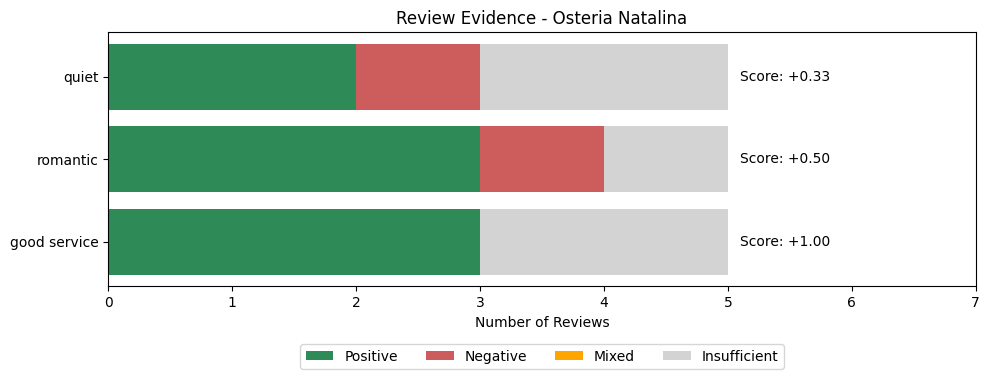

In [27]:
import matplotlib.pyplot as plt

summary = analysis["evidence_summary"]

preferences = list(summary.keys())

positive = [summary[p]["positive"] for p in preferences]
negative = [summary[p]["negative"] for p in preferences]
mixed = [summary[p]["mixed"] for p in preferences]
insufficient = [summary[p]["insufficient"] for p in preferences]

fig, ax = plt.subplots(figsize=(10, 4))

# Create stacked horizontal bars.
ax.barh(preferences, positive, label="Positive", color="seagreen")
ax.barh(preferences, negative, left=positive, label="Negative", color="indianred")

left = [p + n for p, n in zip(positive, negative)]
ax.barh(preferences, mixed, left=left, label="Mixed", color="orange")

left = [p + n + m for p, n, m in zip(positive, negative, mixed)]
ax.barh(preferences, insufficient, left=left, label="Insufficient", color="lightgray")

# Display the numerical preference scores beside each bar.
for i, preference in enumerate(preferences):
    score = analysis["scores"][preference]["score"]
    label = f"Score: {score:+.2f}" if score is not None else "No evidence"
    ax.text(sum(summary[preference].values()) + 0.1, i, label, va="center")

ax.set_title(f"Review Evidence - {analysis['name']}")
ax.set_xlabel("Number of Reviews")
ax.set_xlim(0, max(sum(counts.values()) for counts in summary.values()) + 2)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4)
ax.invert_yaxis()

plt.tight_layout()
#plt.savefig("restaurant_evidence.png", dpi=300, bbox_inches="tight")
plt.show()

In [29]:
from request_parser import parse_request
import json
import time

user_request = (
    "I'm looking for a quiet Italian restaurant in Tampa "
    "for a romantic dinner. Good service is important, "
    "and I'd prefer somewhere rated at least 4 stars."
)

start_time = time.perf_counter()

parsed_request = parse_request(user_request)

elapsed_time = time.perf_counter() - start_time

print(json.dumps(parsed_request, indent=4))
print(f"\nExecution time: {elapsed_time:.2f} seconds")

{
    "cuisine": "Italian",
    "min_stars": 4.0,
    "min_reviews": 0,
    "preferences": [
        "quiet",
        "romantic",
        "good service"
    ]
}

Execution time: 50.33 seconds


In [30]:
from restaurant_search import search_restaurants

candidates = search_restaurants(
    restaurants,
    cuisine=parsed_request["cuisine"],
    min_stars=parsed_request["min_stars"],
    min_reviews=parsed_request["min_reviews"]
)

print(f"Matching restaurants: {len(candidates)}")

for restaurant in candidates[:10]:
    print(
        f"{restaurant['name']:<35} "
        f"Rating: {restaurant['stars']:.1f}  "
        f"Reviews: {restaurant['review_count']}"
    )

Matching restaurants: 109
Mirro's Pizzeria                    Rating: 5.0  Reviews: 111
Amaretto Ristorante                 Rating: 5.0  Reviews: 25
Fat Beet Farm                       Rating: 5.0  Reviews: 24
Williamsburg Cucina Caffe' e Bottega Rating: 5.0  Reviews: 14
Impasto                             Rating: 5.0  Reviews: 5
Chef Tony Macaroni                  Rating: 5.0  Reviews: 5
OLIVIA                              Rating: 4.5  Reviews: 545
Pane Rustica                        Rating: 4.5  Reviews: 468
Osteria Natalina                    Rating: 4.5  Reviews: 400
Due Amici                           Rating: 4.5  Reviews: 350


In [31]:
from unittest.mock import patch
from agent import find_restaurants

with patch("agent.parse_request", return_value=parsed_request):
    agent_result = find_restaurants(user_request, restaurants)

print("Parsed criteria:", agent_result["criteria"])
print("Candidate count:", agent_result["candidate_count"])

for business in agent_result["candidates"][:5]:
    print(
        business["name"],
        business["stars"],
        business["review_count"]
    )

Parsed criteria: {'cuisine': 'Italian', 'min_stars': 4.0, 'min_reviews': 0, 'preferences': ['quiet', 'romantic', 'good service']}
Candidate count: 109
Mirro's Pizzeria 5.0 111
Amaretto Ristorante 5.0 25
Fat Beet Farm 5.0 24
Williamsburg Cucina Caffe' e Bottega 5.0 14
Impasto 5.0 5


In [32]:
eligible = [
    business
    for business in agent_result["candidates"]
    if business["review_count"] >= 50
]

shortlist = eligible[:3]

print(f"Total candidates: {agent_result['candidate_count']}")
print(f"Eligible for analysis: {len(eligible)}")
print("\nShortlisted restaurants:")

for business in shortlist:
    print(
        f"{business['name']:<35} "
        f"Rating: {business['stars']:.1f}  "
        f"Reviews: {business['review_count']}"
    )

Total candidates: 109
Eligible for analysis: 73

Shortlisted restaurants:
Mirro's Pizzeria                    Rating: 5.0  Reviews: 111
OLIVIA                              Rating: 4.5  Reviews: 545
Pane Rustica                        Rating: 4.5  Reviews: 468


In [33]:
from unittest.mock import patch
from agent import find_restaurants

with patch("agent.parse_request", return_value=parsed_request):
    agent_result = find_restaurants(
        user_request,
        restaurants,
        min_evidence_reviews=50,
        shortlist_size=3
    )

print("Matching candidates:", agent_result["candidate_count"])
print("Eligible candidates:", agent_result["eligible_count"])

print("\nShortlisted restaurants:")

for business in agent_result["shortlist"]:
    print(
        f"{business['name']:<35} "
        f"Rating: {business['stars']:.1f}  "
        f"Reviews: {business['review_count']}"
    )

Matching candidates: 109
Eligible candidates: 73

Shortlisted restaurants:
Mirro's Pizzeria                    Rating: 5.0  Reviews: 111
OLIVIA                              Rating: 4.5  Reviews: 545
Pane Rustica                        Rating: 4.5  Reviews: 468


In [34]:
from agent import analyze_candidates
import time

start_time = time.perf_counter()

candidate_analyses = analyze_candidates(
    agent_result,
    reviews_by_business,
    review_limit=2
)

elapsed_time = time.perf_counter() - start_time

print(f"Execution time: {elapsed_time:.2f} seconds")

for restaurant in candidate_analyses:
    print(f"\nRestaurant: {restaurant['name']}")
    print(f"Yelp rating: {restaurant['stars']}")
    print(f"Reviews analyzed: {restaurant['reviews_analyzed']}")

    for preference, result in restaurant["scores"].items():
        score = result["score"]
        score_text = f"{score:+.2f}" if score is not None else "No evidence"

        print(
            f"  {preference:<15} "
            f"Score: {score_text:<12} "
            f"Evidence: {result['evidence_count']}"
        )

Execution time: 173.74 seconds

Restaurant: Mirro's Pizzeria
Yelp rating: 5.0
Reviews analyzed: 1
  quiet           Score: +1.00        Evidence: 1
  romantic        Score: No evidence  Evidence: 0
  good service    Score: No evidence  Evidence: 0

Restaurant: OLIVIA
Yelp rating: 4.5
Reviews analyzed: 2
  quiet           Score: -1.00        Evidence: 1
  romantic        Score: +0.00        Evidence: 2
  good service    Score: +1.00        Evidence: 1

Restaurant: Pane Rustica
Yelp rating: 4.5
Reviews analyzed: 2
  quiet           Score: +0.00        Evidence: 2
  romantic        Score: +1.00        Evidence: 2
  good service    Score: +1.00        Evidence: 1


In [35]:
import importlib.metadata

for package in ["sentence-transformers", "faiss-cpu", "numpy"]:
    try:
        print(package, importlib.metadata.version(package))
    except importlib.metadata.PackageNotFoundError:
        print(package, "NOT INSTALLED")

sentence-transformers 6.0.1
faiss-cpu 1.15.1
numpy 1.26.4


In [36]:
from semantic_retrieval import SemanticReviewSearch
from review_retrieval import get_reviews
import time

business = next(
    b for b in restaurants.values()
    if b["name"] == "Osteria Natalina"
)

reviews = get_reviews(
    reviews_by_business,
    business["business_id"]
)

print("Restaurant:", business["name"])
print("Available reviews:", len(reviews))

start_time = time.perf_counter()

semantic_search = SemanticReviewSearch()
semantic_search.build_index(reviews)

print(f"Index construction time: {time.perf_counter() - start_time:.2f} seconds")
print("Indexed vectors:", semantic_search.index.ntotal)

Restaurant: Osteria Natalina
Available reviews: 408


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

C:\Python310\lib\site-packages\huggingface_hub\file_download.py:129: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\13212\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Index construction time: 7.02 seconds
Indexed vectors: 408


In [37]:
query = "A quiet and peaceful restaurant where people can have a conversation"

results = semantic_search.search(query, limit=5)

for i, result in enumerate(results, start=1):
    review = result["review"]

    print(f"\nResult {i}")
    print(f"Similarity: {result['similarity']:.4f}")
    print(f"Review ID: {review['review_id']}")
    print(f"Yelp stars: {review['stars']}")
    print(f"Review: {review['text'][:500]}")


Result 1
Similarity: 0.5917
Review ID: oIiusP665J3ticKivMIAaw
Yelp stars: 5.0
Review: This is our go to restaurant for special occasions! Great service and you can't beat the food!  Absolutely wonderful everytime!

Result 2
Similarity: 0.5811
Review ID: hpIYq7vXpQnpFrDGkWASoQ
Yelp stars: 4.0
Review: Don't tell anyone about this place!  It's small, friendly and has a very creative and talented kitchen.  The only negative is acoustics. Because it is small and all the surfaces are hard and flat, you really can't have an intimate conversation.  Really bad acoustics are the only reason this place did not get 5 stars.

Result 3
Similarity: 0.5638
Review ID: LOE5NpI0z92XdIzEJdDDxA
Yelp stars: 5.0
Review: This is such a great restaurant. Ive been here twice with friends and the servers are hilarious and super accommodating, I am vegan and they have made me something delicious each time! I believe it's the owner is really from Italy with a strong Italian  accent! Be prepared to wait on a Frida

In [38]:
queries = {
    "quiet": "A quiet restaurant with low noise where people can have a conversation",
    "romantic": "A romantic restaurant with an intimate atmosphere for a date",
    "good service": "A restaurant with attentive, friendly and professional service"
}

for preference, query in queries.items():

    print(f"\nPreference: {preference}")
    print("-" * 60)

    results = semantic_search.search(query, limit=3)

    for result in results:
        review = result["review"]

        print(f"Similarity: {result['similarity']:.4f}")
        print(f"Review ID: {review['review_id']}")
        print(f"Review: {review['text'][:300]}")
        print()


Preference: quiet
------------------------------------------------------------
Similarity: 0.5869
Review ID: hpIYq7vXpQnpFrDGkWASoQ
Review: Don't tell anyone about this place!  It's small, friendly and has a very creative and talented kitchen.  The only negative is acoustics. Because it is small and all the surfaces are hard and flat, you really can't have an intimate conversation.  Really bad acoustics are the only reason this place di

Similarity: 0.5241
Review ID: oIiusP665J3ticKivMIAaw
Review: This is our go to restaurant for special occasions! Great service and you can't beat the food!  Absolutely wonderful everytime!

Similarity: 0.5050
Review ID: AOJrRSw5essHUxgOCMGiQQ
Review: Excellent food and service! Everything was fresh and delicious!!! The restaurant is tiny so I actually like the fact that the owner doesn't allow small children.  I know I can enjoy a meal with my husband and friends without having to make sure our conversation is appropriate for tiny ears.  Looking


Pre

In [39]:
semantic_search = SemanticReviewSearch()
semantic_search.build_index(reviews)

results = semantic_search.search_preferences(
    queries,
    limit_per_preference=3
)

print("Total retrievals:", len(queries) * 3)
print("Unique reviews:", len(results))

for result in results:
    review = result["review"]

    print(f"\nReview ID: {review['review_id']}")
    print("Similarities:", result["similarities"])
    print("Text:", review["text"][:200])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Total retrievals: 9
Unique reviews: 7

Review ID: hpIYq7vXpQnpFrDGkWASoQ
Similarities: {'quiet': 0.5869114398956299}
Text: Don't tell anyone about this place!  It's small, friendly and has a very creative and talented kitchen.  The only negative is acoustics. Because it is small and all the surfaces are hard and flat, you

Review ID: oIiusP665J3ticKivMIAaw
Similarities: {'quiet': 0.5240722894668579, 'romantic': 0.5824339389801025, 'good service': 0.6879570484161377}
Text: This is our go to restaurant for special occasions! Great service and you can't beat the food!  Absolutely wonderful everytime!

Review ID: AOJrRSw5essHUxgOCMGiQQ
Similarities: {'quiet': 0.5050081014633179}
Text: Excellent food and service! Everything was fresh and delicious!!! The restaurant is tiny so I actually like the fact that the owner doesn't allow small children.  I know I can enjoy a meal with my hus

Review ID: tc1aOH1_x10QOiDSE8tdUQ
Similarities: {'romantic': 0.6186277866363525}
Text: This is a top-notch I

In [43]:
from restaurant_analysis import analyze_restaurant
from semantic_retrieval import SemanticReviewSearch
import time

preferences = ["quiet", "romantic", "good service"]

queries = {
    "quiet": "A quiet restaurant with low noise where people can have a conversation",
    "romantic": "A romantic restaurant with an intimate atmosphere for a date",
    "good service": "A restaurant with attentive, friendly and professional service"
}

semantic_search = SemanticReviewSearch()

start_time = time.perf_counter()

analysis = analyze_restaurant(
    business,
    reviews_by_business,
    preferences,
    review_limit=1,
    semantic_search=semantic_search,
    preference_queries=queries
)

elapsed_time = time.perf_counter() - start_time

print(f"Execution time: {elapsed_time:.2f} seconds")
print("Restaurant:", analysis["name"])
print("Reviews analyzed:", analysis["reviews_analyzed"])

for preference, result in analysis["scores"].items():
    print(
        preference,
        "Score:", result["score"],
        "Evidence:", result["evidence_count"]
    )

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Execution time: 89.04 seconds
Restaurant: Osteria Natalina
Reviews analyzed: 3
quiet Score: -1.0 Evidence: 1
romantic Score: 1.0 Evidence: 1
good service Score: 1.0 Evidence: 3


In [44]:
from review_analysis import analyze_reviews_batch
from evidence_aggregation import aggregate_evidence
from restaurant_scoring import score_restaurant
import time

matches = semantic_search.search_preferences(
    queries,
    limit_per_preference=1
)

selected_reviews = [
    match["review"]
    for match in matches
]

print("Reviews selected:", len(selected_reviews))

start_time = time.perf_counter()

batch_analyses = analyze_reviews_batch(
    selected_reviews,
    preferences
)

elapsed_time = time.perf_counter() - start_time

batch_summary = aggregate_evidence(batch_analyses)
batch_scores = score_restaurant(batch_summary)

print(f"Batch execution time: {elapsed_time:.2f} seconds")

for preference, result in batch_scores.items():
    print(
        preference,
        "Score:", result["score"],
        "Evidence:", result["evidence_count"]
    )

Reviews selected: 3
Batch execution time: 74.69 seconds
quiet Score: -1.0 Evidence: 1
romantic Score: 0.0 Evidence: 2
good service Score: 1.0 Evidence: 2


In [45]:
for analysis in batch_analyses:

    print("\nReview ID:", analysis["review_id"])

    for preference, result in analysis["results"].items():
        print(
            f"  {preference:<15}"
            f"{result['classification']:<15}"
            f"{result['explanation']}"
        )


Review ID: hpIYq7vXpQnpFrDGkWASoQ
  quiet          negative       The review explicitly states bad acoustics that prevent intimate conversation, indicating the place is not quiet.
  romantic       negative       Bad acoustics prevent intimate conversation, which is essential for a romantic atmosphere.
  good service   insufficient   The review mentions the restaurant being 'friendly' but does not explicitly discuss service quality. The rule states not to infer positive service from the absence of complaints or from the word 'friendly'.

Review ID: tc1aOH1_x10QOiDSE8tdUQ
  quiet          insufficient   The review does not mention acoustics or noise level, so there is no evidence to determine quietness.
  romantic       positive       The review explicitly states that the restaurant is a place to take a significant other for a special occasion and was used for an anniversary, indicating it is suitable for romantic settings.
  good service   positive       The review mentions 'premier se

In [47]:
from restaurant_analysis import analyze_restaurant
from semantic_retrieval import SemanticReviewSearch
import time

semantic_search = SemanticReviewSearch()

start_time = time.perf_counter()

analysis = analyze_restaurant(
    business,
    reviews_by_business,
    preferences,
    review_limit=1,
    semantic_search=semantic_search,
    preference_queries=queries
)

elapsed_time = time.perf_counter() - start_time

print(f"Execution time: {elapsed_time:.2f} seconds")
print("Restaurant:", analysis["name"])
print("Reviews analyzed:", analysis["reviews_analyzed"])

for preference, result in analysis["scores"].items():
    print(
        preference,
        "Score:", result["score"],
        "Evidence:", result["evidence_count"]
    )

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Execution time: 47.35 seconds
Restaurant: Osteria Natalina
Reviews analyzed: 3
quiet Score: -1.0 Evidence: 1
romantic Score: 0.0 Evidence: 2
good service Score: 1.0 Evidence: 3


In [48]:
import json

with open("last_batch_response.json", "r", encoding="utf-8") as file:
    response = json.load(file)

expected = set(preferences)

for review in response["reviews"]:
    actual = set(review["results"])

    print("Review:", review["review_id"])
    print("Valid preferences:", actual == expected)
    print("Returned:", sorted(actual))
    print()

Review: hpIYq7vXpQnpFrDGkWASoQ
Valid preferences: True
Returned: ['good service', 'quiet', 'romantic']

Review: tc1aOH1_x10QOiDSE8tdUQ
Valid preferences: True
Returned: ['good service', 'quiet', 'romantic']

Review: oIiusP665J3ticKivMIAaw
Valid preferences: True
Returned: ['good service', 'quiet', 'romantic']



In [49]:
from restaurant_ranking import rank_restaurants

test_analyses = [
    {
        "name": "Mirro's Pizzeria",
        "stars": 5.0,
        "review_count": 111,
        "scores": {
            "quiet": {"score": 1.0, "evidence_count": 1},
            "romantic": {"score": None, "evidence_count": 0},
            "good service": {"score": None, "evidence_count": 0}
        }
    },
    {
        "name": "OLIVIA",
        "stars": 4.5,
        "review_count": 545,
        "scores": {
            "quiet": {"score": -1.0, "evidence_count": 1},
            "romantic": {"score": 0.0, "evidence_count": 2},
            "good service": {"score": 1.0, "evidence_count": 1}
        }
    },
    {
        "name": "Pane Rustica",
        "stars": 4.5,
        "review_count": 468,
        "scores": {
            "quiet": {"score": 0.0, "evidence_count": 2},
            "romantic": {"score": 1.0, "evidence_count": 2},
            "good service": {"score": 1.0, "evidence_count": 1}
        }
    }
]

preferences = ["quiet", "romantic", "good service"]

ranked = rank_restaurants(test_analyses, preferences)

for position, restaurant in enumerate(ranked, start=1):

    print(
        f"{position}. {restaurant['name']} "
        f"(Overall: {restaurant['overall_score']:+.4f})"
    )

    for preference, score in restaurant["adjusted_scores"].items():
        print(f"   {preference:<15} {score:+.4f}")

1. Pane Rustica (Overall: +0.2167)
   quiet           +0.0000
   romantic        +0.4000
   good service    +0.2500
2. Mirro's Pizzeria (Overall: +0.0833)
   quiet           +0.2500
   romantic        +0.0000
   good service    +0.0000
3. OLIVIA (Overall: +0.0000)
   quiet           -0.2500
   romantic        +0.0000
   good service    +0.2500


In [53]:
from agent import recommend_candidates
import time

queries = {
    "quiet": "A quiet restaurant with low noise where people can have a conversation",
    "romantic": "A romantic restaurant with an intimate atmosphere for a date",
    "good service": "A restaurant with attentive, friendly and professional service"
}

start_time = time.perf_counter()

recommendation_result = recommend_candidates(
    agent_result,
    reviews_by_business,
    review_limit=1,
    preference_queries=queries
)

elapsed_time = time.perf_counter() - start_time

print(f"\nTotal execution time: {elapsed_time:.2f} seconds")
print("Restaurants analyzed:", len(recommendation_result["recommendations"]))

for position, restaurant in enumerate(
    recommendation_result["recommendations"],
    start=1
):

    print(
        f"\n{position}. {restaurant['name']}"
        f" (Yelp: {restaurant['stars']}, "
        f"Overall: {restaurant['overall_score']:+.4f})"
    )

    print("Reviews analyzed:", restaurant["reviews_analyzed"])

    for preference, result in restaurant["scores"].items():

        raw_score = result["score"]
        adjusted_score = restaurant["adjusted_scores"][preference]

        print(
            f"  {preference:<15}"
            f"Raw: {str(raw_score):<8}"
            f"Adjusted: {adjusted_score:+.4f} "
            f"Evidence: {result['evidence_count']}"
        )

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Batches:   0%|          | 0/18 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]


Total execution time: 31.98 seconds
Restaurants analyzed: 3

1. OLIVIA (Yelp: 4.5, Overall: +0.1333)
Reviews analyzed: 3
  quiet          Raw: -1.0    Adjusted: -0.2500 Evidence: 1
  romantic       Raw: 1.0     Adjusted: +0.2500 Evidence: 1
  good service   Raw: 1.0     Adjusted: +0.4000 Evidence: 2

2. Mirro's Pizzeria (Yelp: 5.0, Overall: +0.0556)
Reviews analyzed: 3
  quiet          Raw: None    Adjusted: +0.0000 Evidence: 0
  romantic       Raw: None    Adjusted: +0.0000 Evidence: 0
  good service   Raw: 0.3333333333333333Adjusted: +0.1667 Evidence: 3

3. Pane Rustica (Yelp: 4.5, Overall: -0.1611)
Reviews analyzed: 3
  quiet          Raw: -1.0    Adjusted: -0.4000 Evidence: 2
  romantic       Raw: -1.0    Adjusted: -0.2500 Evidence: 1
  good service   Raw: 0.3333333333333333Adjusted: +0.1667 Evidence: 3


In [51]:
from pathlib import Path

response_file = Path("last_batch_response.json")

print("File exists:", response_file.exists())

if response_file.exists():
    response = response_file.read_text(encoding="utf-8")

    print("Response length:", len(response))
    print("\nRaw Qwen3 response:")
    print(response[:5000])

File exists: True
Response length: 1476

Raw Qwen3 response:
{
  "Z7Yi14uqNRcT9TmZ7uxu8A": {
    "quiet": {
      "status": "negative",
      "explanation": "The restaurant is too noisy for intimate conversations as stated in the review."
    },
    "romantic": {
      "status": "negative",
      "explanation": "The noise level prevents a romantic atmosphere for conversations."
    },
    "good service": {
      "status": "positive",
      "explanation": "Review states 'the service was excellent'."
    }
  },
  "Sb8fVjrVIAQC03judnvXdQ": {
    "quiet": {
      "status": "negative",
      "explanation": "Atmosphere described as 'great for large groups to gib gab over some cocktails', indicating loud environment."
    },
    "romantic": {
      "status": "insufficient",
      "explanation": "No mention of romantic atmosphere; focuses on group dining and modern industrial feel."
    },
    "good service": {
      "status": "positive",
      "explanation": "Server described as 'a true enter

In [52]:
import json
from review_analysis import normalize_batch_response

with open("last_batch_response.json", "r", encoding="utf-8") as file:
    raw_response = json.load(file)

test_reviews = [
    {"review_id": review_id}
    for review_id in raw_response
]

normalized = normalize_batch_response(
    raw_response,
    test_reviews
)

print("Normalized reviews:", len(normalized["reviews"]))

for review in normalized["reviews"]:
    print(
        review["review_id"],
        list(review["results"]),
        review["results"]["quiet"]["classification"]
    )

Normalized reviews: 3
Z7Yi14uqNRcT9TmZ7uxu8A ['quiet', 'romantic', 'good service'] negative
Sb8fVjrVIAQC03judnvXdQ ['quiet', 'romantic', 'good service'] negative
rYngdUBfvnAKADlR5BRDtQ ['quiet', 'romantic', 'good service'] insufficient


In [55]:
from agent import recommend_candidates
import time

start = time.perf_counter()

result = recommend_candidates(
    agent_result,
    reviews_by_business,
    review_limit=1,
    preference_queries=queries
)

print(f"\nExecution time: {time.perf_counter() - start:.2f} seconds")

for restaurant in result["recommendations"]:
    print(
        restaurant["name"],
        f"{restaurant['overall_score']:+.4f}"
    )

Analyzing: Mirro's Pizzeria


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Analyzing: OLIVIA


Batches:   0%|          | 0/18 [00:00<?, ?it/s]

Analyzing: Pane Rustica


Batches:   0%|          | 0/16 [00:00<?, ?it/s]


Execution time: 28.32 seconds
OLIVIA +0.1333
Mirro's Pizzeria +0.0556
Pane Rustica -0.1611


In [56]:
from agent import recommend_candidates
import time

start = time.perf_counter()

result = recommend_candidates(
    agent_result,
    reviews_by_business,
    review_limit=1,
    preference_queries=queries
)

print(f"\nExecution time: {time.perf_counter() - start:.2f} seconds")

for restaurant in result["recommendations"]:
    print(
        restaurant["name"],
        f"{restaurant['overall_score']:+.4f}"
    )

Cache hit: Mirro's Pizzeria
Cache hit: OLIVIA
Cache hit: Pane Rustica

Execution time: 0.02 seconds
OLIVIA +0.1333
Mirro's Pizzeria +0.0556
Pane Rustica -0.1611


In [59]:
from agent_decision import decide_next_action
import time

preferences = ["quiet", "romantic", "good service"]

start = time.perf_counter()

decision = decide_next_action(
    preferences=preferences,
    ranked_restaurants=result["recommendations"],
    remaining_candidates=98,
    rounds_completed=1,
    max_rounds=3
)

print("Decision:", decision["action"])
print("Reason:", decision["reason"])
print(f"Decision time: {time.perf_counter() - start:.2f} seconds")

Decision: search_more
Reason: The current recommendations have negative evidence for 'quiet' (score -1.0) in OLIVIA and Pane Rustica, and insufficient evidence for 'romantic' in Mirro's Pizzeria. Important preferences have negative or incomplete evidence, so more restaurants should be investigated.
Decision time: 3.16 seconds


In [60]:
#Test 1: Maximum search rounds reached
decision = decide_next_action(
    preferences=preferences,
    ranked_restaurants=result["recommendations"],
    remaining_candidates=98,
    rounds_completed=3,
    max_rounds=3
)

print(decision)

#Test 2: No remaining candidates
decision = decide_next_action(
    preferences=preferences,
    ranked_restaurants=result["recommendations"],
    remaining_candidates=0,
    rounds_completed=1,
    max_rounds=3
)

print(decision)

{'action': 'finish', 'reason': 'Maximum search rounds reached.'}
{'action': 'finish', 'reason': 'No additional restaurant candidates remain.'}


In [61]:
from agent import find_restaurants

agent_result = find_restaurants(
    "I want a quiet, romantic Italian restaurant with good service.",
    restaurants
)

print("Eligible:", agent_result["eligible_count"])
print("Stored candidates:", len(agent_result["eligible_candidates"]))

print("\nFirst six eligible restaurants:")
for business in agent_result["eligible_candidates"][:6]:
    print(business["name"])

Eligible: 101
Stored candidates: 101

First six eligible restaurants:
Mirro's Pizzeria
OLIVIA
Pane Rustica
Osteria Natalina
Due Amici
Oggi Italian


In [62]:
from agent import run_agent
import time

start = time.perf_counter()

agent_run = run_agent(
    agent_result,
    reviews_by_business,
    review_limit=1,
    batch_size=3,
    max_rounds=1
)

print("\nRestaurants analyzed:", agent_run["restaurants_analyzed"])
print("Decision history:", agent_run["decision_history"])
print(f"Elapsed: {time.perf_counter() - start:.2f} seconds")


Agent round 1
Analyzing 3 restaurants...
Cache hit: Mirro's Pizzeria
Cache hit: OLIVIA
Cache hit: Pane Rustica
Agent decision: finish
Reason: Maximum search rounds reached.

Restaurants analyzed: 3
Decision history: [{'round': 1, 'action': 'finish', 'reason': 'Maximum search rounds reached.'}]
Elapsed: 0.26 seconds


In [66]:
start = time.perf_counter()

agent_run = run_agent(
    agent_result,
    reviews_by_business,
    review_limit=1,
    batch_size=3,
    max_rounds=2
)

print("\nRestaurants analyzed:", agent_run["restaurants_analyzed"])

print("\nDecision history:")
for decision in agent_run["decision_history"]:
    print(decision)

print("\nFinal ranking:")
for restaurant in agent_run["recommendations"]:
    print(
        restaurant["name"],
        f"{restaurant['overall_score']:+.4f}"
    )

print(f"\nElapsed: {time.perf_counter() - start:.2f} seconds")


Agent round 1
Analyzing 3 restaurants...
Cache hit: Mirro's Pizzeria
Cache hit: OLIVIA
Cache hit: Pane Rustica
Agent decision: search_more
Reason: The current recommendations have negative evidence for 'romantic' at 'Mirro's Pizzeria' and insufficient evidence for 'quiet' (only one negative score). Additionally, the 'quiet' preference has negative evidence across multiple restaurants, indicating it's not satisfied yet.

Agent round 2
Analyzing 3 restaurants...
Cache hit: Osteria Natalina
Analyzing: Due Amici


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

Analyzing: Oggi Italian


Batches:   0%|          | 0/12 [00:00<?, ?it/s]

Agent decision: finish
Reason: Maximum search rounds reached.

Restaurants analyzed: 6

Decision history:
{'round': 1, 'action': 'search_more', 'reason': "The current recommendations have negative evidence for 'romantic' at 'Mirro's Pizzeria' and insufficient evidence for 'quiet' (only one negative score). Additionally, the 'quiet' preference has negative evidence across multiple restaurants, indicating it's not satisfied yet."}
{'round': 2, 'action': 'finish', 'reason': 'Maximum search rounds reached.'}

Final ranking:
Oggi Italian +0.2667
OLIVIA +0.1944
Pane Rustica +0.1667
Osteria Natalina +0.1333
Due Amici +0.0556
Mirro's Pizzeria -0.0333

Elapsed: 24.73 seconds


In [64]:
import json

with open("last_batch_response.json", "r", encoding="utf-8") as file:
    response = json.load(file)

print(json.dumps(response, indent=2))

{
  "reviews": [
    {
      "review_id": "3HiZYQS4TorOKs4yEBCA7Q",
      "results": {
        "quiet": "negative",
        "romantic": "insufficient",
        "good service": "negative"
      }
    },
    {
      "review_id": "thEDHN_sLISx4Xei9t87gA",
      "results": {
        "quiet": "insufficient",
        "romantic": "positive",
        "good service": "positive"
      }
    },
    {
      "review_id": "G-ht6SrdU4nGg5ldAJSZAw",
      "results": {
        "quiet": "insufficient",
        "romantic": "insufficient",
        "good service": "positive"
      }
    }
  ]
}


In [65]:
from review_analysis import normalize_batch_response

with open("last_batch_response.json", "r", encoding="utf-8") as file:
    parsed = json.load(file)

normalized = normalize_batch_response(parsed, [])

print(json.dumps(normalized, indent=2))

{
  "reviews": [
    {
      "review_id": "3HiZYQS4TorOKs4yEBCA7Q",
      "results": {
        "quiet": {
          "classification": "negative",
          "explanation": ""
        },
        "romantic": {
          "classification": "insufficient",
          "explanation": ""
        },
        "good service": {
          "classification": "negative",
          "explanation": ""
        }
      }
    },
    {
      "review_id": "thEDHN_sLISx4Xei9t87gA",
      "results": {
        "quiet": {
          "classification": "insufficient",
          "explanation": ""
        },
        "romantic": {
          "classification": "positive",
          "explanation": ""
        },
        "good service": {
          "classification": "positive",
          "explanation": ""
        }
      }
    },
    {
      "review_id": "G-ht6SrdU4nGg5ldAJSZAw",
      "results": {
        "quiet": {
          "classification": "insufficient",
          "explanation": ""
        },
        "romantic": {
     

## Figure 2
Figure 2. Evidence-based restaurant ranking following two rounds of LLM-driven agent execution. The initial shortlist contained three restaurants. After evaluating the available review evidence, the agent selected search_more and analyzed three additional candidates. Oggi Italian, discovered during the second round, achieved the highest adjusted preference score (+0.2667), demonstrating how iterative investigation can change the final recommendation.

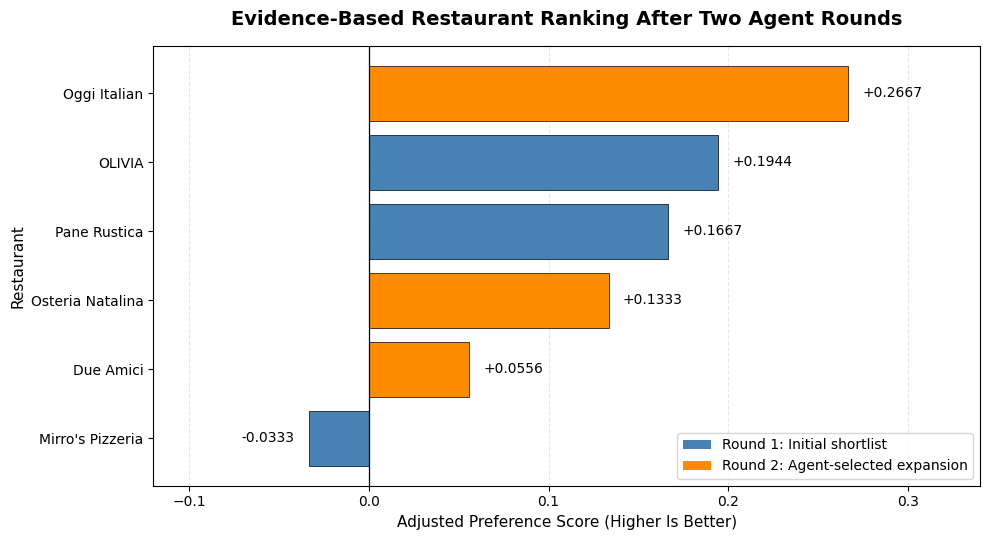

In [67]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Results from the completed agent execution.
recommendations = agent_run["recommendations"]

# Identify restaurants investigated in each round.
first_round_ids = {
    business["business_id"]
    for business in agent_result["eligible_candidates"][:3]
}

# Reverse the ranking so the highest score appears at the top.
ranked = list(reversed(recommendations))

names = [restaurant["name"] for restaurant in ranked]
scores = [restaurant["overall_score"] for restaurant in ranked]

colors = [
    "steelblue" if restaurant["business_id"] in first_round_ids
    else "darkorange"
    for restaurant in ranked
]

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    names,
    scores,
    color=colors,
    edgecolor="black",
    linewidth=0.5
)

# Zero indicates neutral aggregate evidence.
ax.axvline(0, color="black", linewidth=0.9)

# Display numerical scores beside each bar.
for bar, score in zip(bars, scores):
    x_offset = 0.008 if score >= 0 else -0.008
    ax.text(
        score + x_offset,
        bar.get_y() + bar.get_height() / 2,
        f"{score:+.4f}",
        va="center",
        ha="left" if score >= 0 else "right",
        fontsize=10
    )

ax.set_title(
    "Evidence-Based Restaurant Ranking After Two Agent Rounds",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Adjusted Preference Score (Higher Is Better)", fontsize=11)
ax.set_ylabel("Restaurant", fontsize=11)

ax.set_xlim(-0.12, 0.34)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.legend(
    handles=[
        Patch(facecolor="steelblue", label="Round 1: Initial shortlist"),
        Patch(facecolor="darkorange", label="Round 2: Agent-selected expansion")
    ],
    loc="lower right"
)

plt.tight_layout()

# Save for the report, appendix, and presentation.
plt.savefig("agent_ranking_two_rounds.png", dpi=300, bbox_inches="tight")
plt.savefig("agent_ranking_two_rounds.pdf", bbox_inches="tight")

plt.show()

## PRINT PDF

In [57]:
import os
from nbconvert import PDFExporter
import nbformat

NOTEBOOK_NAME = "tester_Ben_Prishtina.ipynb"
NOTEBOOK_PATH = NOTEBOOK_NAME

# Read the notebook as UTF-8
with open(NOTEBOOK_PATH, encoding="utf-8") as f:
    nb_node = nbformat.read(f, as_version=4)

# Set PDF document title
nb_node.metadata["title"] = "Appendix: CAP 6938 - Final Project Tester"

pdf_exporter = PDFExporter()
pdf_data, resources = pdf_exporter.from_notebook_node(nb_node)

NOTEBOOK_PDF = NOTEBOOK_PATH.rsplit('.', 1)[0] + '.pdf'
with open(NOTEBOOK_PDF, "wb") as f:
    f.write(pdf_data)
    
print(f"PDF CREATED: {NOTEBOOK_PDF}")

PDF CREATED: tester_Ben_Prishtina.pdf
